# EPL 2024-25 Player Stats: Exploratory Analysis

**Goal:** Explore Premier League player and club performance, with a focus on scoring, carrying and goalkeeping.

**Data:** 562 players, 57 columns of per-player season stats (source: https://www.kaggle.com/datasets/aesika/english-premier-league-player-stats-2425).

**Tools:** Python, pandas, seaborn, matplotlib

In [1]:
#Imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline 

In [2]:
#Load dataset

epl_df = pd.read_csv('data/epl_player_stats_24_25.csv')
epl_df.head()

,Player Name,Club,Nationality,Position,Appearances,Minutes,Goals,Assists,Shots,Shots On Target,...,Fouls,Yellow Cards,Red Cards,Saves,Saves %,Penalties Saved,Clearances Off Line,Punches,High Claims,Goals Prevented
0,Ben White,Arsenal,England,DEF,17,1198,0,2,9,12,...,10,2,0,0,0%,0,0,0,0,0.0
1,Bukayo Saka,Arsenal,England,MID,25,1735,6,10,67,2,...,15,3,0,0,0%,0,0,0,0,0.0
2,David Raya,Arsenal,Spain,GKP,38,3420,0,0,0,0,...,1,3,0,86,72%,0,0,8,53,2.1
3,Declan Rice,Arsenal,England,MID,35,2833,4,7,48,18,...,21,5,1,0,0%,0,0,0,0,0.0
4,Ethan Nwaneri,Arsenal,England,MID,26,889,4,0,24,0,...,9,1,0,0,0%,0,0,0,0,0.0


In [3]:
epl_df['Club'] = epl_df['Club'].replace({'Brighton': 'Brighton & Hove Albion'}) #Cleaning data set

## Data Quality

In [ ]:
pct_cols = ['Conversion %', 'Passes%', 'Crosses %', 'fThird Passes %',
            'gDuels %', 'aDuels %', 'Saves %']
epl_df[pct_cols] = epl_df[pct_cols].apply(lambda s: s.str.rstrip('%').astype(float))

# outfielders have no saves, so "0%" isn't real
epl_df.loc[epl_df['Position'] != 'GKP', 'Saves %'] = np.nan

In [ ]:
checks = {
    'SOT > Shots':             epl_df['Shots On Target'] > epl_df['Shots'],
    'Goals > SOT':             epl_df['Goals'] > epl_df['Shots On Target'],
    'Passes made > attempted': epl_df['Successful Passes'] > epl_df['Passes'],
    'Prog carries > Carries':  epl_df['Progressive Carries'] > epl_df['Carries'],
    'Duels won > Duels':       epl_df['gDuels Won'] > epl_df['Ground Duels'],
    'Minutes > 90*Apps':       epl_df['Minutes'] > 90 * epl_df['Appearances'],
}
pd.Series({k: v.sum() for k, v in checks.items()})

In [ ]:
# Goals scored (GF) in the final 2024-25 Premier League table
official_goals = pd.Series({
    'Liverpool': 86, 'Arsenal': 69, 'Manchester City': 72, 'Chelsea': 64,
    'Newcastle United': 68, 'Aston Villa': 58, 'Nottingham Forest': 58,
    'Brighton & Hove Albion': 66, 'Bournemouth': 58, 'Brentford': 66,
    'Fulham': 54, 'Crystal Palace': 51, 'Everton': 42, 'West Ham United': 46,
    'Manchester United': 44, 'Wolverhampton Wanderers': 54,
    'Tottenham Hotspur': 64, 'Leicester City': 33, 'Ipswich Town': 36,
    'Southampton': 26,
})
assert official_goals.sum() == 1115   # season total; fails loudly if you mistype

check = pd.DataFrame({'dataset': epl_df.groupby('Club')['Goals'].sum(),
                      'official': official_goals})
check['missing'] = check['official'] - check['dataset']
check.sort_values('missing', ascending=False)

In [4]:
epl_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 562 entries, 0 to 561
Data columns (total 57 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Player Name                562 non-null    str    
 1   Club                       562 non-null    str    
 2   Nationality                562 non-null    str    
 3   Position                   562 non-null    str    
 4   Appearances                562 non-null    int64  
 5   Minutes                    562 non-null    int64  
 6   Goals                      562 non-null    int64  
 7   Assists                    562 non-null    int64  
 8   Shots                      562 non-null    int64  
 9   Shots On Target            562 non-null    int64  
 10  Conversion %               562 non-null    str    
 11  Big Chances Missed         562 non-null    int64  
 12  Hit Woodwork               562 non-null    int64  
 13  Offsides                   562 non-null    int64  
 14  Touch

In [5]:
epl_df.describe()

,Appearances,Minutes,Goals,Assists,Shots,Shots On Target,Big Chances Missed,Hit Woodwork,Offsides,Touches,...,Own Goals,Fouls,Yellow Cards,Red Cards,Saves,Penalties Saved,Clearances Off Line,Punches,High Claims,Goals Prevented
count,562.000000,562.000000,562.000000,562.000000,562.000000,562.000000,562.000000,562.000000,562.000000,562.000000,...,562.000000,562.000000,562.000000,562.000000,562.000000,562.000000,562.000000,562.000000,562.000000,562.000000
mean,20.581851,1336.208185,1.713523,1.145907,17.526690,5.514235,2.135231,0.496441,2.250890,857.033808,...,0.058719,14.295374,2.756228,0.092527,4.161922,0.024911,0.145907,0.467972,1.304270,0.068505
std,12.136239,1055.099340,3.310674,2.197891,22.342341,9.407054,3.732051,0.986986,4.085456,729.009027,...,0.277056,15.040111,2.750985,0.307913,18.616319,0.187160,0.473986,2.832182,6.230133,0.635313
min,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,-4.200000
25%,10.000000,336.750000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,199.250000,...,0.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,22.000000,1156.000000,0.000000,0.000000,10.000000,1.000000,1.000000,0.000000,1.000000,700.500000,...,0.000000,10.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,32.000000,2229.250000,2.000000,2.000000,25.000000,7.000000,3.000000,1.000000,3.000000,1356.750000,...,0.000000,22.000000,4.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
max,38.000000,3420.000000,29.000000,18.000000,130.000000,61.000000,27.000000,6.000000,28.000000,3347.000000,...,3.000000,73.000000,12.000000,2.000000,153.000000,2.000000,3.000000,28.000000,56.000000,6.000000


In [6]:
epl_df.isna().sum()

Player Name                  0
Club                         0
Nationality                  0
Position                     0
Appearances                  0
Minutes                      0
Goals                        0
Assists                      0
Shots                        0
Shots On Target              0
Conversion %                 0
Big Chances Missed           0
Hit Woodwork                 0
Offsides                     0
Touches                      0
Passes                       0
Successful Passes            0
Passes%                      0
Crosses                      0
Successful Crosses           0
Crosses %                    0
fThird Passes                0
Successful fThird Passes     0
fThird Passes %              0
Through Balls                0
Carries                      0
Progressive Carries          0
Carries Ended with Goal      0
Carries Ended with Assist    0
Carries Ended with Shot      0
Carries Ended with Chance    0
Possession Won               0
Disposse

In [7]:
epl_df["Min_per_match"]=(epl_df["Minutes"]/epl_df["Appearances"]).astype(int)
epl_df["Goals_per_90"]=((epl_df["Goals"]/epl_df["Minutes"])*90).astype(float)
epl_df.head()

,Player Name,Club,Nationality,Position,Appearances,Minutes,Goals,Assists,Shots,Shots On Target,...,Red Cards,Saves,Saves %,Penalties Saved,Clearances Off Line,Punches,High Claims,Goals Prevented,Min_per_match,Goals_per_90
0,Ben White,Arsenal,England,DEF,17,1198,0,2,9,12,...,0,0,0%,0,0,0,0,0.0,70,0.000000
1,Bukayo Saka,Arsenal,England,MID,25,1735,6,10,67,2,...,0,0,0%,0,0,0,0,0.0,69,0.311239
2,David Raya,Arsenal,Spain,GKP,38,3420,0,0,0,0,...,0,86,72%,0,0,8,53,2.1,90,0.000000
3,Declan Rice,Arsenal,England,MID,35,2833,4,7,48,18,...,1,0,0%,0,0,0,0,0.0,80,0.127074
4,Ethan Nwaneri,Arsenal,England,MID,26,889,4,0,24,0,...,0,0,0%,0,0,0,0,0.0,34,0.404949


In [8]:
Total_goals = epl_df["Goals"].sum()
print(Total_goals)

963


In [9]:
Total_shots = epl_df['Shots'].sum()
print(Total_shots)

9850


In [10]:
Target_shots = epl_df["Shots On Target"].sum()
print(Target_shots)

3099


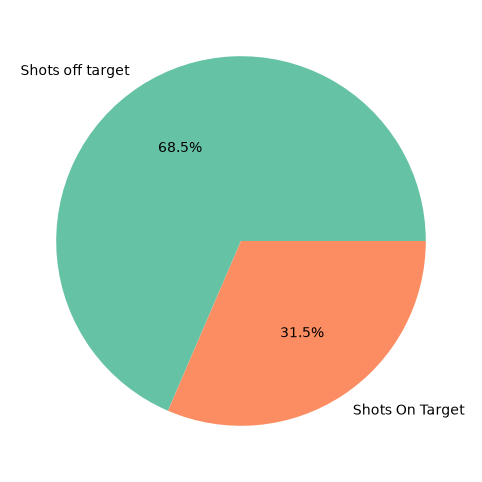

In [11]:
plt.figure(figsize=(10,6))
shots_not_on_target = epl_df['Shots'].sum() - Target_shots
shot_split = [shots_not_on_target, Target_shots]
labels = ['Shots off target','Shots On Target']
color = sns.color_palette("Set2")
plt.pie(shot_split,labels=labels,colors=color,autopct='%.1f%%')
plt.show()

In [12]:
epl_df["Position"].unique()

<StringArray>
['DEF', 'MID', 'GKP', 'FWD']
Length: 4, dtype: str

In [13]:
epl_df[epl_df['Position'] == 'FWD']

,Player Name,Club,Nationality,Position,Appearances,Minutes,Goals,Assists,Shots,Shots On Target,...,Red Cards,Saves,Saves %,Penalties Saved,Clearances Off Line,Punches,High Claims,Goals Prevented,Min_per_match,Goals_per_90
5,Gabriel Jesus,Arsenal,Brazil,FWD,17,603,3,0,20,0,...,0,0,0%,0,0,0,0,0.0,35,0.447761
11,Kai Havertz,Arsenal,Germany,FWD,23,1874,9,3,53,2,...,0,0,0%,0,0,0,0,0.0,81,0.432231
17,Nathan Butler-Oyedeji,Arsenal,England,FWD,1,6,0,0,1,0,...,0,0,0%,0,0,0,0,0.0,6,0.000000
30,Donyell Malen,Aston Villa,Netherlands,FWD,14,298,3,0,15,0,...,0,0,0%,0,0,0,0,0.0,21,0.906040
36,Jhon Durán,Aston Villa,Colombia,FWD,20,626,7,0,31,0,...,1,0,0%,0,0,0,0,0.0,31,1.006390
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
508,Danny Ings,West Ham United,England,FWD,15,270,1,2,14,0,...,0,0,0%,0,0,0,0,0.0,18,0.333333
511,Evan Ferguson,West Ham United,Ireland,FWD,21,387,1,0,12,0,...,0,0,0%,0,0,0,0,0.0,18,0.232558
524,Michail Antonio,West Ham United,Jamaica,FWD,14,844,1,1,19,0,...,0,0,0%,0,0,0,0,0.0,60,0.106635
526,Niclas Füllkrug,West Ham United,Germany,FWD,18,788,3,2,16,0,...,0,0,0%,0,0,0,0,0.0,43,0.342640


In [14]:
np.size((epl_df["Nationality"].unique()))

64

<Axes: xlabel='Nationality'>

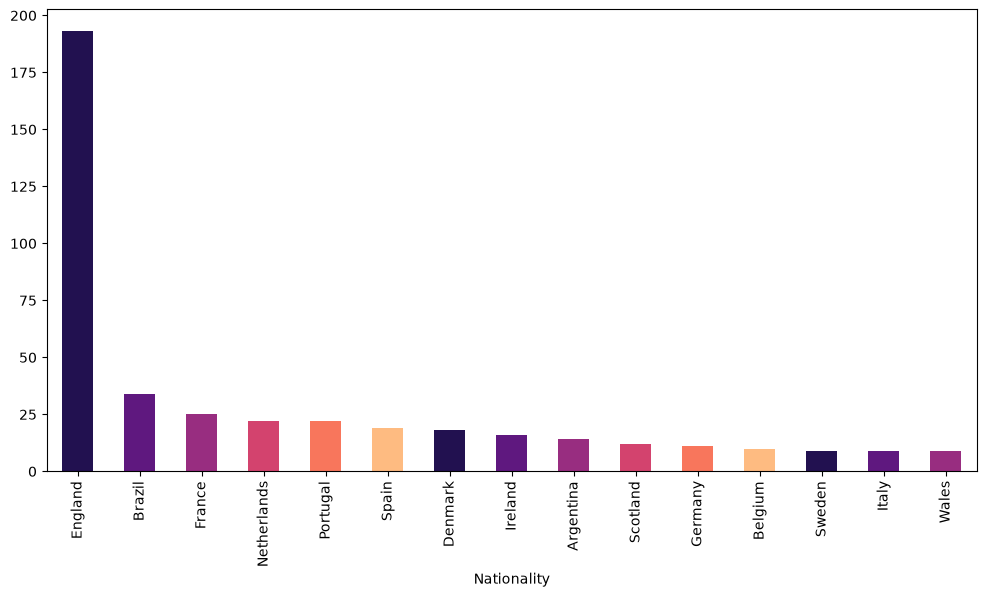

In [15]:
nationality = epl_df.groupby("Nationality").size().sort_values(ascending=False)
nationality.head(15).plot(kind = "bar" , figsize=(12,6), color = sns.color_palette('magma'))


<Axes: xlabel='Club'>

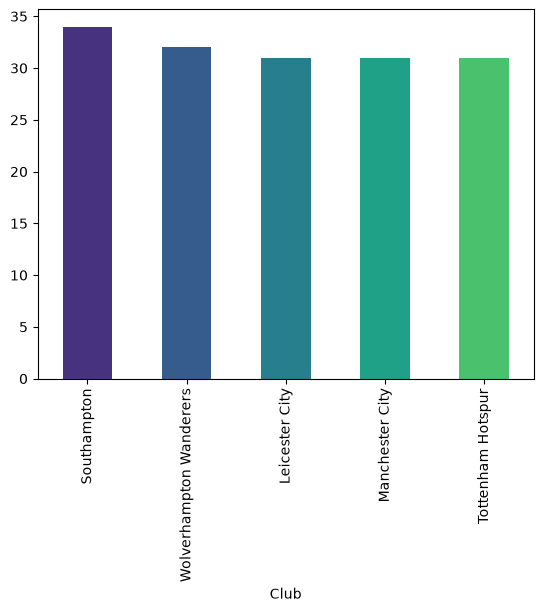

In [16]:
epl_df['Club'].value_counts().nlargest(5).plot(kind = 'bar',color= sns.color_palette('viridis'))

<Axes: xlabel='Club'>

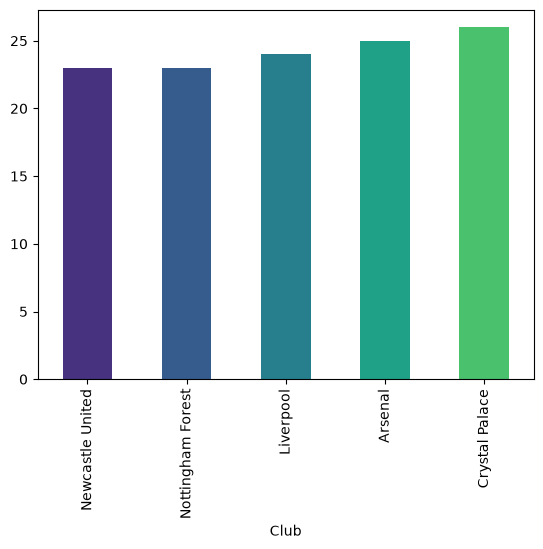

In [17]:
epl_df['Club'].value_counts().nsmallest(5).plot(kind = 'bar',color= sns.color_palette('viridis'))

In [18]:
#Meant to be age but realized the dataset does not have an age column, switching to appearances
less20_apps = epl_df[epl_df["Appearances"]<= 20]
apps20to25 = epl_df[(epl_df["Appearances"]> 20)& (epl_df["Appearances"]<=25)]
apps25to30 = epl_df[(epl_df["Appearances"]> 25)& (epl_df["Appearances"]<=30)]
apps30to35 = epl_df[(epl_df["Appearances"]> 30)& (epl_df["Appearances"]<=35)]
above35 = epl_df[epl_df["Appearances"]>35]

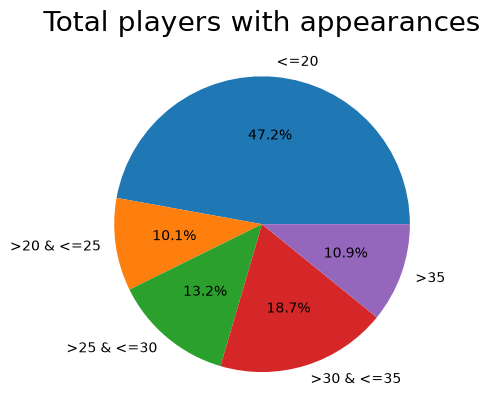

In [19]:
x = np.array([less20_apps["Player Name"].count(),apps20to25["Player Name"].count(),apps25to30["Player Name"].count(),apps30to35["Player Name"].count(),above35["Player Name"].count()])
mylabels = ['<=20','>20 & <=25','>25 & <=30', '>30 & <=35','>35']
plt.title("Total players with appearances", fontsize = 20)
plt.pie(x,labels = mylabels, autopct="%.1f%%")
plt.show()

<Axes: xlabel='Club'>

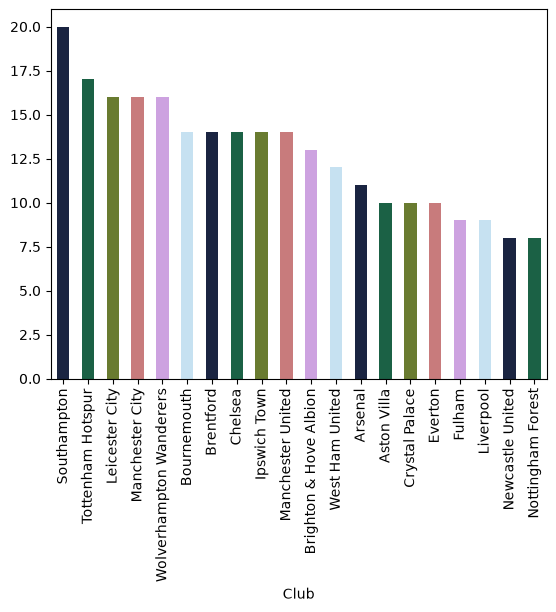

In [20]:
under20_apps = epl_df[epl_df["Appearances"]<20]
under20_apps['Club'].value_counts().plot(kind = 'bar', color = sns.color_palette("cubehelix"))

([0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19],
 [Text(0, 0, 'Arsenal'),
  Text(1, 0, 'Aston Villa'),
  Text(2, 0, 'Bournemouth'),
  Text(3, 0, 'Brentford'),
  Text(4, 0, 'Brighton & Hove Albion'),
  Text(5, 0, 'Chelsea'),
  Text(6, 0, 'Crystal Palace'),
  Text(7, 0, 'Everton'),
  Text(8, 0, 'Fulham'),
  Text(9, 0, 'Ipswich Town'),
  Text(10, 0, 'Leicester City'),
  Text(11, 0, 'Liverpool'),
  Text(12, 0, 'Manchester City'),
  Text(13, 0, 'Manchester United'),
  Text(14, 0, 'Newcastle United'),
  Text(15, 0, 'Nottingham Forest'),
  Text(16, 0, 'Southampton'),
  Text(17, 0, 'Tottenham Hotspur'),
  Text(18, 0, 'West Ham United'),
  Text(19, 0, 'Wolverhampton Wanderers')])

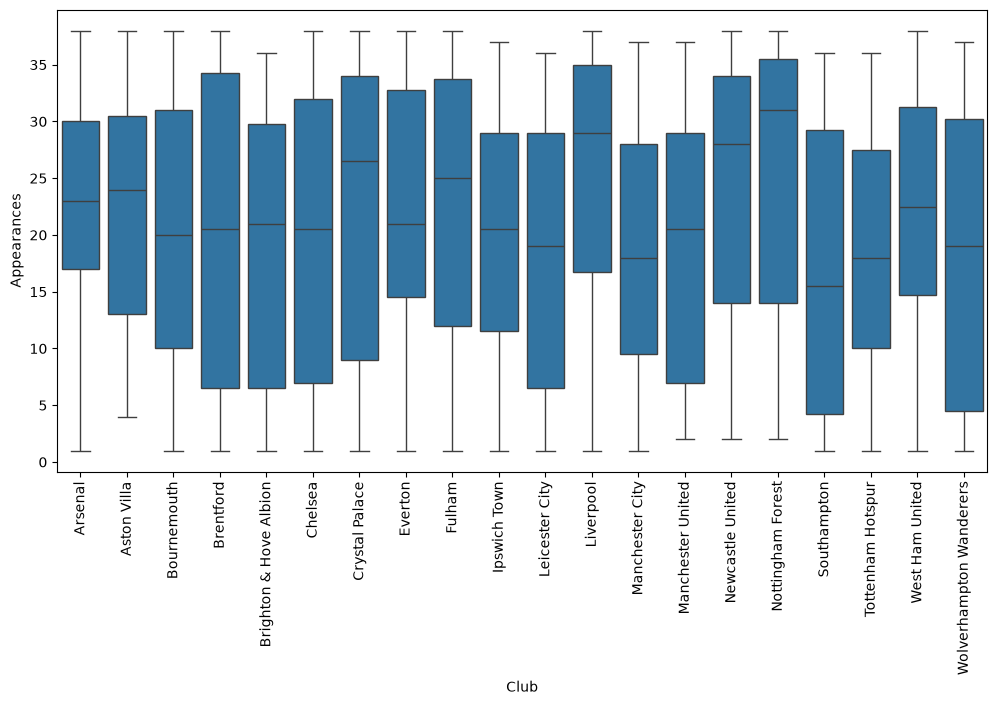

In [21]:
plt.figure(figsize=(12,6))
sns.boxplot(x="Club", y= "Appearances", data= epl_df)
plt.xticks(rotation = 90)

In [22]:
avg_apps_by_club = epl_df.groupby('Club')['Appearances'].mean().sort_values(ascending=False)
avg_apps_by_club

Club
Nottingham Forest          25.521739
Newcastle United           24.826087
Liverpool                  24.291667
Fulham                     23.038462
Arsenal                    22.440000
Crystal Palace             22.346154
Aston Villa                22.148148
West Ham United            21.928571
Everton                    21.846154
Bournemouth                20.275862
Chelsea                    20.142857
Brentford                  20.000000
Ipswich Town               19.866667
Brighton & Hove Albion     19.233333
Manchester United          18.800000
Tottenham Hotspur          18.580645
Manchester City            18.290323
Wolverhampton Wanderers    18.281250
Leicester City             18.000000
Southampton                16.764706
Name: Appearances, dtype: float64

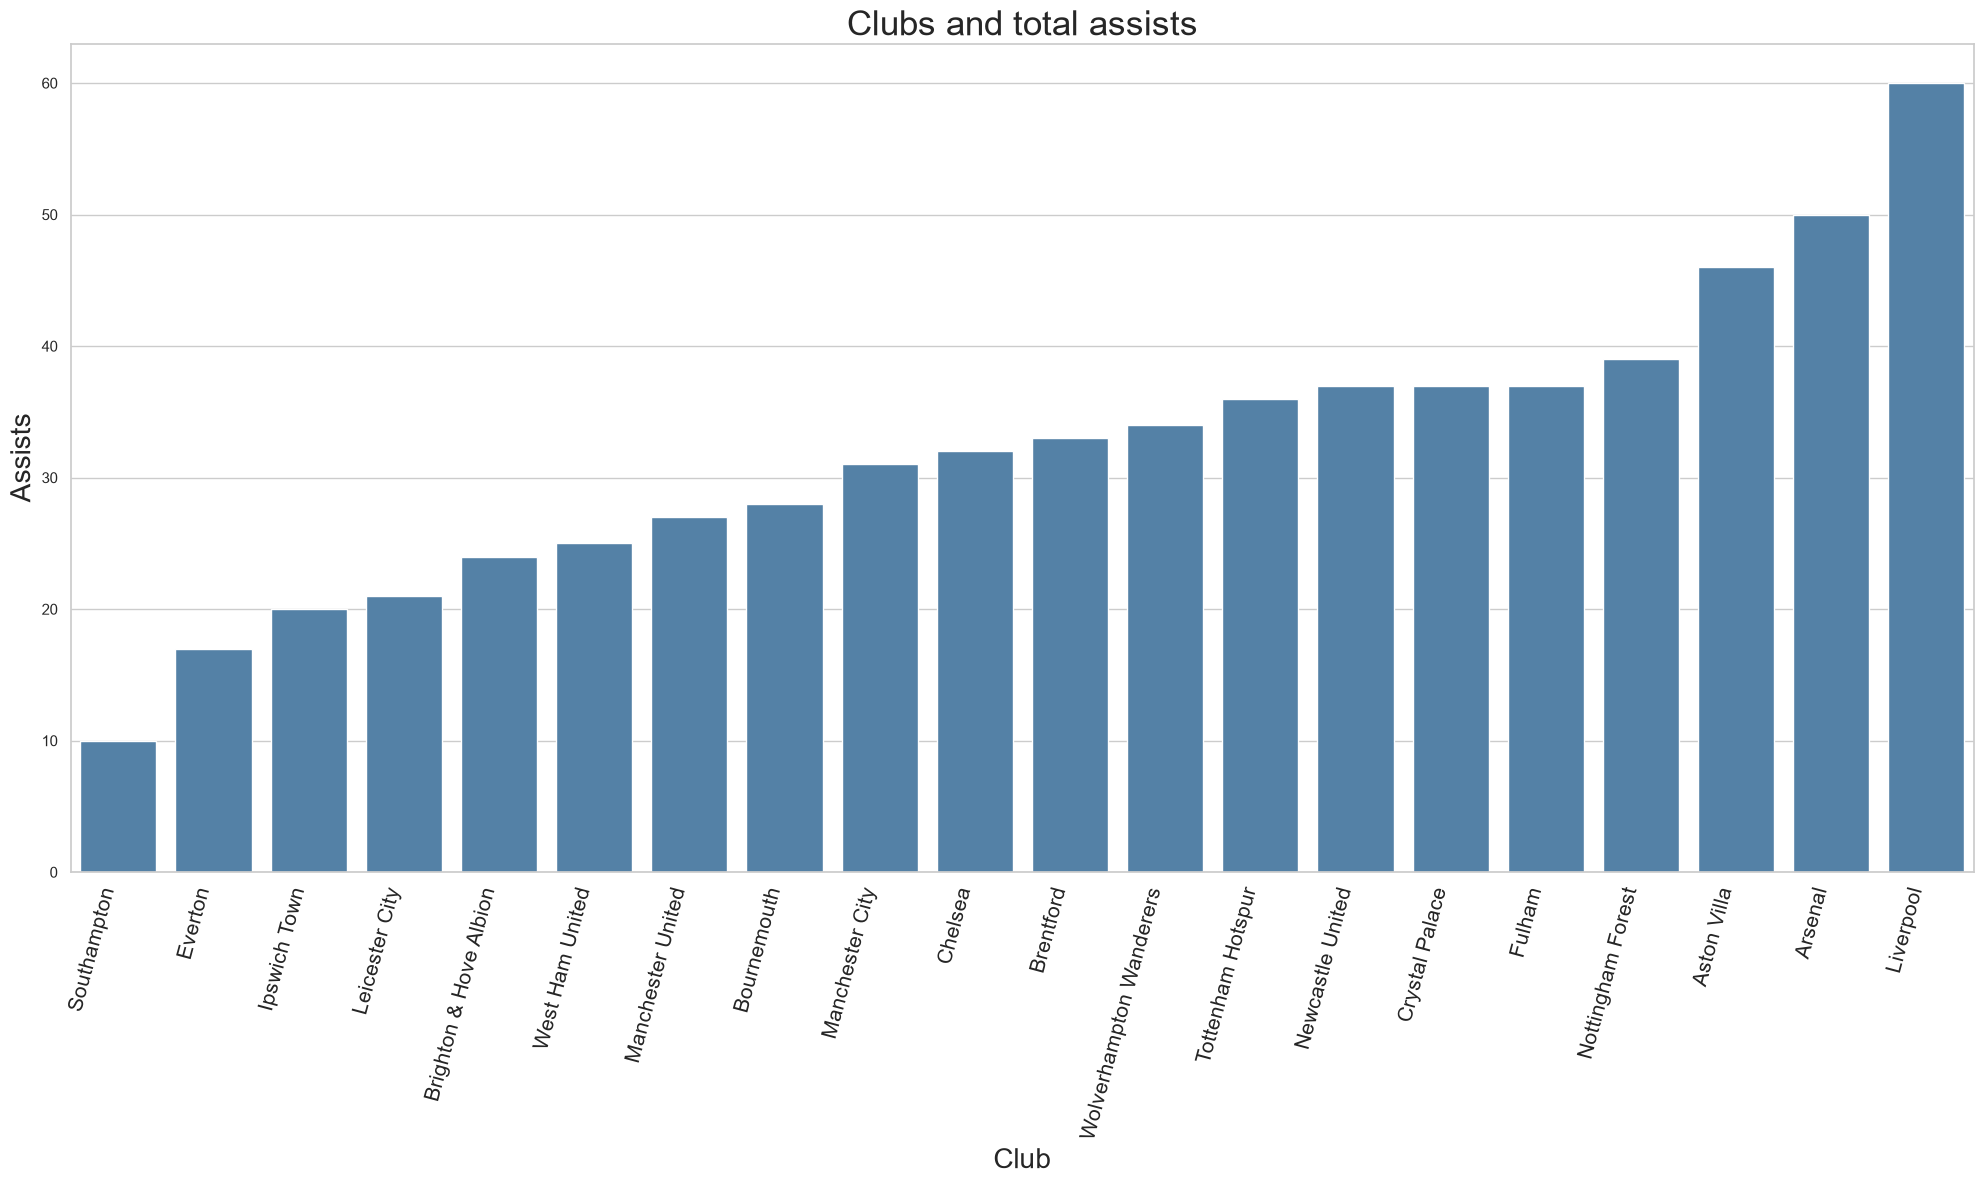

In [23]:
assists = (epl_df.groupby('Club', as_index=False)['Assists'].sum()
           .sort_values('Assists'))

sns.set_theme(style='whitegrid')
plt.figure(figsize=(20, 12))                      # size first
ax = sns.barplot(x='Club', y='Assists', data=assists, color='steelblue')

ax.set_xlabel('Club', fontsize=20)
ax.set_ylabel('Assists', fontsize=20)
ax.set_title('Clubs and total assists', fontsize=25)
plt.xticks(rotation=75, ha='right',fontsize=15)              # ha='right' lines labels up under their bars
plt.tight_layout()
plt.show()

In [24]:
#Top 10 assists
top10_assists = epl_df[["Player Name","Club","Assists","Appearances"]].nlargest(n=10,columns = "Assists")
top10_assists

,Player Name,Club,Assists,Appearances
324,Mohamed Salah,Liverpool,18,38
399,Jacob Murphy,Newcastle United,12,35
415,Anthony Elanga,Nottingham Forest,11,38
1,Bukayo Saka,Arsenal,10,25
45,Morgan Rogers,Aston Villa,10,37
99,Mikkel Damsgaard,Brentford,10,38
222,Antonee Robinson,Fulham,10,36
367,Bruno Fernandes,Manchester United,10,36
497,Son Heung-Min,Tottenham Hotspur,9,30
14,Martin Ødegaard,Arsenal,8,30


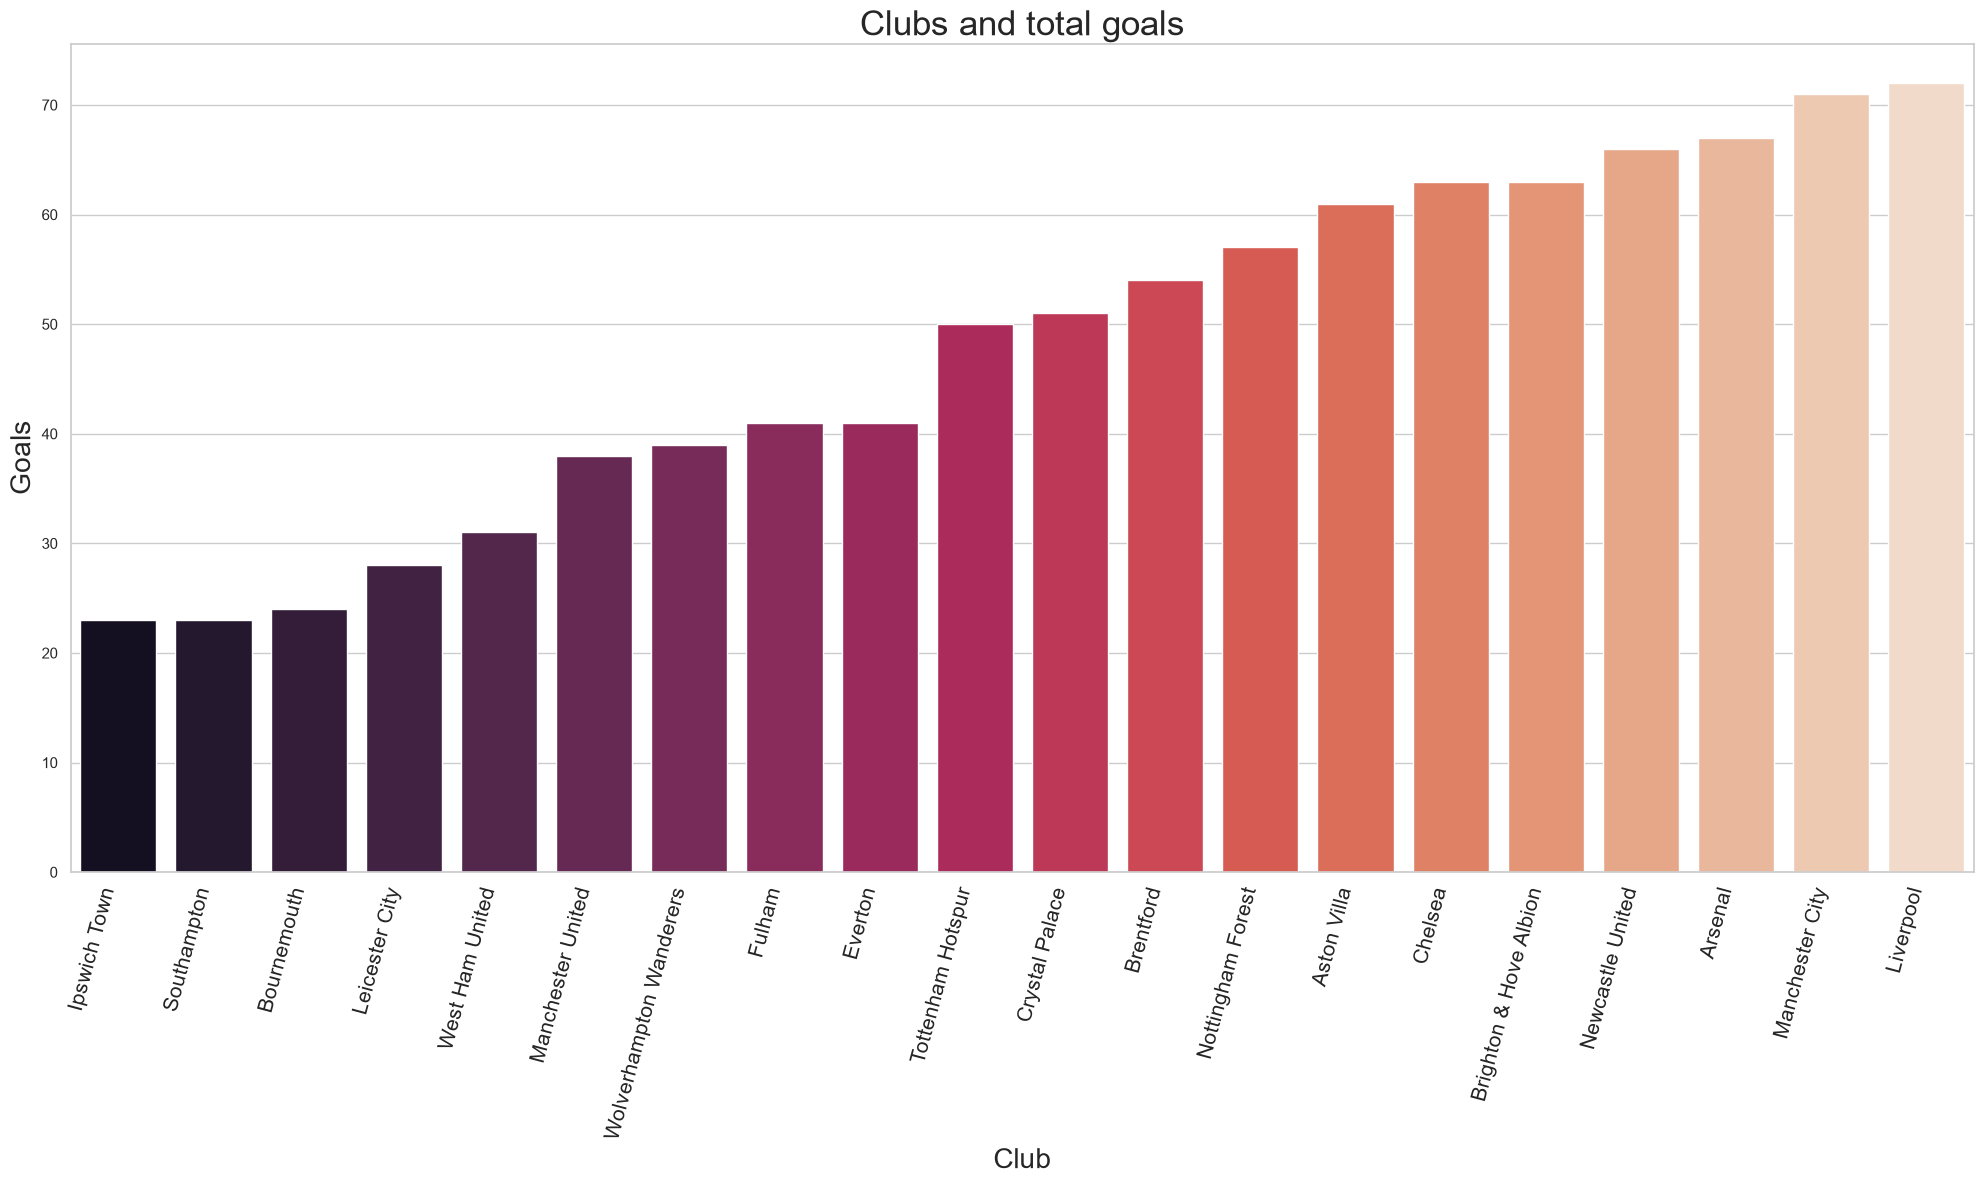

In [25]:
goals = (epl_df.groupby('Club', as_index=False)['Goals'].sum()
           .sort_values('Goals'))

sns.set_theme(style='whitegrid')
plt.figure(figsize=(20, 12))                      # size first
ax = sns.barplot(x='Club', y='Goals', data=goals,hue='Club', palette="rocket")

ax.set_xlabel('Club', fontsize=20)
ax.set_ylabel('Goals', fontsize=20)
ax.set_title('Clubs and total goals', fontsize=25)
plt.xticks(rotation=75, ha='right',fontsize=15)              # ha='right' lines labels up under their bars
plt.tight_layout()
plt.show()

In [26]:
top10_goals = epl_df[["Player Name","Club","Goals","Appearances"]].nlargest(n=10, columns="Goals")
top10_goals

,Player Name,Club,Goals,Appearances
324,Mohamed Salah,Liverpool,29,38
391,Alexander Isak,Newcastle United,23,34
335,Erling Haaland,Manchester City,22,31
82,Bryan Mbeumo,Brentford,20,38
417,Chris Wood,Nottingham Forest,20,36
107,Yoane Wissa,Brentford,19,35
46,Ollie Watkins,Aston Villa,16,38
141,Cole Palmer,Chelsea,15,37
548,Matheus Cunha,Wolverhampton Wanderers,15,33
180,Jean-Philippe Mateta,Crystal Palace,14,37


In [27]:
top10_goals_per_90 = (epl_df[epl_df['Minutes'] >= 900]
                      .nlargest(10, 'Goals_per_90')
                      [['Player Name', 'Club', 'Goals', 'Minutes', 'Goals_per_90']])
top10_goals_per_90

,Player Name,Club,Goals,Minutes,Goals_per_90
324,Mohamed Salah,Liverpool,29,3377,0.772875
238,Rodrigo Muniz,Fulham,8,951,0.757098
391,Alexander Isak,Newcastle United,23,2769,0.747562
335,Erling Haaland,Manchester City,22,2741,0.722364
417,Chris Wood,Nottingham Forest,20,2976,0.604839
107,Yoane Wissa,Brentford,19,2927,0.584216
46,Ollie Watkins,Aston Villa,16,2610,0.551724
351,Omar Marmoush,Manchester City,7,1182,0.532995
82,Bryan Mbeumo,Brentford,20,3415,0.527086
548,Matheus Cunha,Wolverhampton Wanderers,15,2600,0.519231


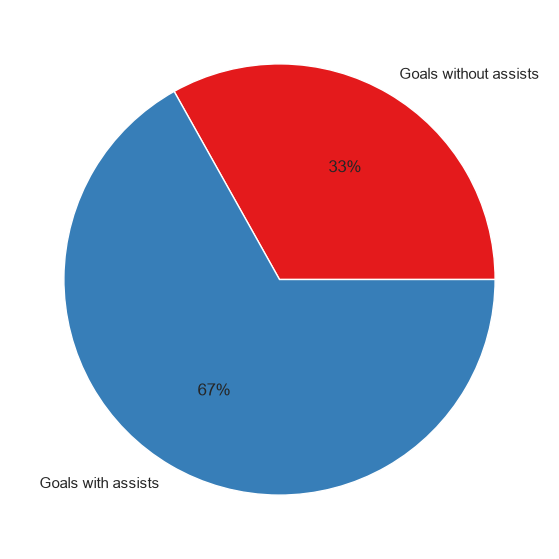

In [28]:
plt.figure(figsize=(14,7))
assist = epl_df["Assists"].sum()
goal_split = [Total_goals - assist,assist]
labels = ["Goals without assists" , 'Goals with assists']
color = sns.color_palette("Set1")
plt.pie(goal_split, labels = labels, colors= color , autopct="%.0f%%")
plt.show()

<Axes: title={'center': 'Players with the most yellows'}, xlabel='Player Name', ylabel='Number of yellow cards'>

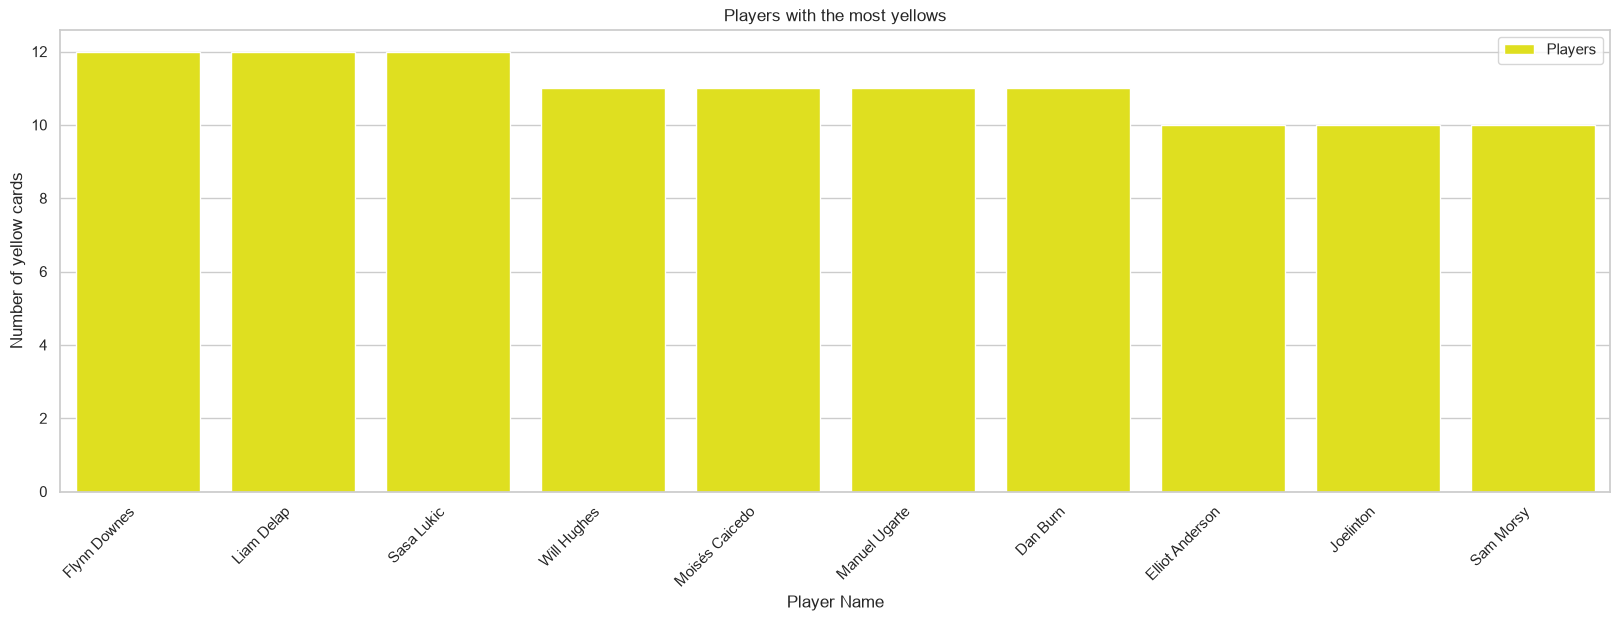

In [29]:
yellows = epl_df.sort_values(by="Yellow Cards",ascending=False)[:10]
plt.figure(figsize=(20,6))
plt.title("Players with the most yellows")
c=sns.barplot(x=yellows["Player Name"], y=yellows["Yellow Cards"], label= 'Players',color='yellow')
plt.ylabel("Number of yellow cards")
plt.xticks(rotation=45, ha='right')
c;